# StockWise-ML: Stock Price Prediction\n**Goal:** estimate the next trading day's closing price from historical OHLCV data and technical indicators.\n\n**Dataset notice:** this notebook ships with a *synthetic illustrative dataset* so it can run without internet. Results are not real stock-market performance and are not financial advice.

In [1]:
# StockWise-ML: Next-Day Closing Price Prediction
# IMPORTANT: Included data is synthetic demo data. Replace it with a real ticker dataset before claiming real-market results.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from pathlib import Path

DATA_PATH = Path("data/demo_stock_data.csv")
df = pd.read_csv(DATA_PATH, parse_dates=["Date"])
df.head()


## 1. Data overview\nThe sample file contains Date, Open, High, Low, Close and Volume.

In [2]:
df.describe()\n

In [3]:
plt.figure(figsize=(10,4))\nplt.plot(df['Date'], df['Close'])\nplt.title('Synthetic Demo Closing Price')\nplt.xlabel('Date'); plt.ylabel('Price'); plt.tight_layout(); plt.show()\n

## 2. Feature engineering\nWe calculate daily return, moving averages (5/20 days), RSI (14), and rolling volatility (20). The target is the next trading day's close.

In [4]:
def add_features(data):
    data = data.copy().sort_values("Date")
    data["Return_1d"] = data["Close"].pct_change()
    data["SMA_5"] = data["Close"].rolling(5).mean()
    data["SMA_20"] = data["Close"].rolling(20).mean()
    delta = data["Close"].diff()
    avg_gain = delta.clip(lower=0).rolling(14).mean()
    avg_loss = (-delta.clip(upper=0)).rolling(14).mean()
    rs = avg_gain / (avg_loss + 1e-9)
    data["RSI_14"] = 100 - (100 / (1 + rs))
    data["Volatility_20"] = data["Return_1d"].rolling(20).std()
    data["Target"] = data["Close"].shift(-1)  # next trading day's close
    return data.dropna()

data = add_features(df)
feature_cols = ["Open", "High", "Low", "Volume", "Return_1d", "SMA_5", "SMA_20", "RSI_14", "Volatility_20"]
data[feature_cols + ["Target"]].head()


## 3. Train/test split\nAn 80/20 chronological split is used. No random shuffling is performed, avoiding look-ahead leakage.

In [5]:
# Chronological split: never shuffle time-series rows.
split_idx = int(len(data) * 0.80)
train = data.iloc[:split_idx]
test = data.iloc[split_idx:]
X_train, y_train = train[feature_cols], train["Target"]
X_test, y_test = test[feature_cols], test["Target"]
print(f"Training rows: {len(train)} | Test rows: {len(test)}")


Training rows: 863 | Test rows: 216

## 4. Model training and evaluation\nWe compare Linear Regression, Random Forest and Gradient Boosting using MAE, RMSE and R². Lower MAE/RMSE is better; R² is closer to 1 when predictions explain more variance.

In [6]:
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=120, max_depth=8, min_samples_leaf=3, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=100, max_depth=2, learning_rate=0.05, random_state=42),
}
scores = []
predictions = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    predictions[name] = y_pred
    scores.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, y_pred),
        "RMSE": mean_squared_error(y_test, y_pred) ** 0.5,
        "R2": r2_score(y_test, y_pred)
    })
results = pd.DataFrame(scores).sort_values("RMSE")
results


            Model      MAE     RMSE       R2
Linear Regression 1.343291 1.717323 0.959574
    Random Forest 1.433084 1.827609 0.954215
Gradient Boosting 1.436424 1.831080 0.954041

## 5. Prediction visualization

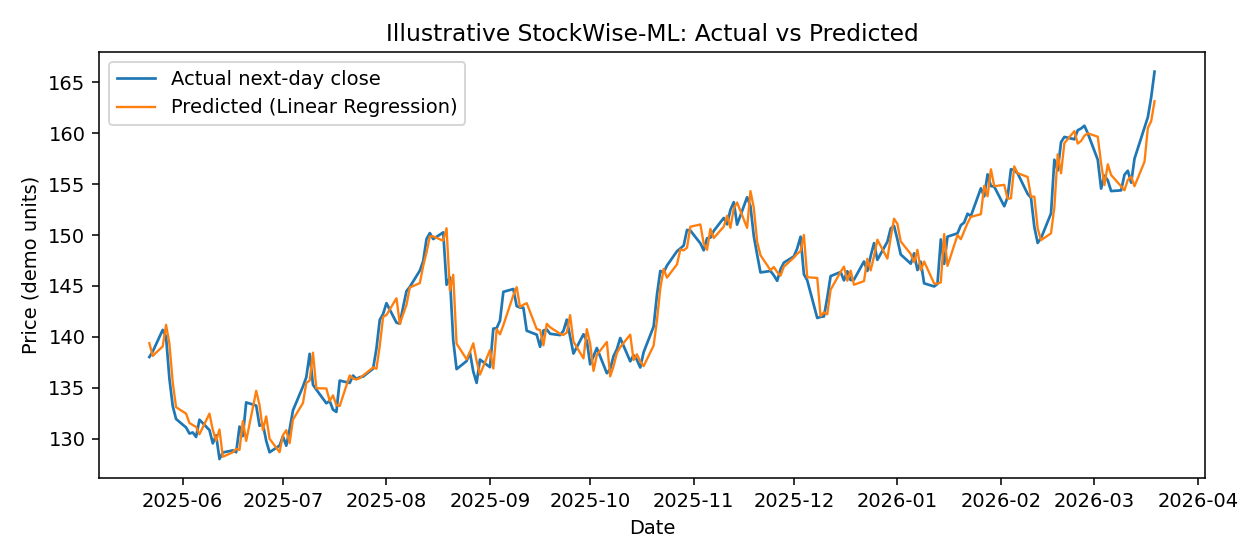

In [7]:
best_model_name = results.iloc[0]["Model"]
actual = y_test.values
predicted = predictions[best_model_name]
plt.figure(figsize=(12, 4))
plt.plot(test["Date"], actual, label="Actual", linewidth=1.5)
plt.plot(test["Date"], predicted, label=f"Predicted — {best_model_name}", linewidth=1.2)
plt.title("Actual vs Predicted Next-Day Close (Demo Data)")
plt.xlabel("Date"); plt.ylabel("Price"); plt.legend(); plt.grid(alpha=0.25); plt.tight_layout()
plt.show()


## 6. Optional real-data replacement\nThe code below is optional. If internet access and yfinance are available, fetch a real ticker, save it locally, and rerun the analysis. Do not report synthetic demo scores as real-market results.

In [8]:
# Optional: replace demo data with a real market ticker.
# If internet/package access is available, uncomment and run:
# !pip install yfinance
# import yfinance as yf
# real = yf.download("RELIANCE.NS", start="2019-01-01", auto_adjust=True, progress=False)
# real = real.reset_index()
# real.columns = [str(c[0] if isinstance(c, tuple) else c).title() for c in real.columns]
# real.to_csv("data/reliance_real_data.csv", index=False)
# Then set DATA_PATH to that CSV and rerun the notebook.


## Conclusion\nThis workflow demonstrates a reproducible time-series regression pipeline. Stock prices are noisy and affected by news, macroeconomics and market structure. A model's historical test performance does not guarantee future returns.